## Energie Based Model

# Deux grandes catégories d'EBM

Il existe deux grandes catégories d'EBM. 
- Les EBM autorégressifs
- Les EBM non autorégressifs

Dans ce notebook je m'attaque aux EBM autorégressifs. 

# Deux approches d'entrainements

Il existe deux grandes aproches pour entraîner un EBM :
- l'approche probabiliste
- l'approche contrastive

Je développe ici l'approche contrastive.

# L'approche contrastive and inference



# Contrastive Learning

Dans le notebook de présentation je présente les EBM. L'entraînement contrastive d'un EBM-AR (EBM-AutoRégressif) est supervisé. Le réseau de neurone prend en entrée le couple de donnée $(x,y)$. Il est entraîné à minimiser l'énergie de de toute paire correspondante $(x,y_{positif})$ et à  minimiser celle de toute paire non correspondante $(x,y_{negatif})$. L'entrainement se fait de la même manière que dans le cas d'un réseau de neurone stndard avec la descente de gradient etc...
A l'exception aussi que la fonction objective ici c'est l'énergie. Aussi une particularité est qu'un réseau EBM-AR a en entrée $(x,y)$ et en sortie "un scalaire" (nombre réel). Le réseau modélise donc une fonction sclaire. $E_{\theta}(x,y) \in R$.


###  Entraînement (Ajuster les poids $\theta$ du réseau)

Une fois qu'on a le bon $y_{\text{pos}}$ et un mauvais candidat $y_{\text{neg}}$ (généré à l'étape 1 ou tiré aléatoirement), on met à jour les poids $\theta$.

Considérons la perte contrastive :

$$L(\theta) = E_\theta(x, y_{\text{pos}}) - E_\theta(x, y_{\text{neg}})$$

* **Forward :**
* Calcul de l'énergie vraie : $E_{\text{pos}} = E_\theta(x, y_{\text{pos}})$
* Calcul de l'énergie fausse : $E_{\text{neg}} = E_\theta(x, y_{\text{neg}})$


* **Backward (Gradients par rapport aux poids) :**

$$\frac{\partial L}{\partial \theta} = \frac{\partial E_\theta(x, y_{\text{pos}})}{\partial \theta} - \frac{\partial E_\theta(x, y_{\text{neg}})}{\partial \theta}$$

* **Mise à jour des poids :**

$$\theta \leftarrow \theta - \alpha \frac{\partial L}{\partial \theta}$$

* Le terme $+\frac{\partial E_{\text{pos}}}{\partial \theta}$ baisse l'énergie pour la vraie paire.
* Le terme $-\frac{\partial E_{\text{neg}}}{\partial \theta}$ augmente l'énergie pour la fausse paire.


# Inférence

Pendant l'inférence, les poids du réseau $\theta$ sont gelés. On fait la retropropagation du gradient de $E$ par rapport à l'entrée candidate $y$.
# Forward : 
On passe $x$ et $y^{(k)}$ dans le réseau. Il calcule $E(x, y^{(k)})$.
# Backward : 
On calcule le gradient par rapport à $y$ :$$\nabla_y E = \frac{\partial E(x, y^{(k)})}{\partial y}$$Mise à jour : On déplace le candidat $y$ dans la direction qui diminue l'énergie :$$y^{(k+1)} = y^{(k)} - \eta \, \nabla_y E$$On répète $K$ fois jusqu'à atteindre le minimum voulu $y^*$.

In [1]:
pip install torch



[notice] A new release of pip is available: 26.0.1 -> 26.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import torch
import torch.nn as nn

In [3]:
#1 Energie Based Model 
class EBM(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2,64), nn.SiLU(), nn.Linear(64,1)
                                 )
    def forward(self, x, y):
        return self.net(torch.cat([x,y], dim=-1))
    # Learning
    def sample_negatives(self, x, n_steps=20, step_size=0.1, noise_scale=0.01):
        y = torch.empty_like(x).uniform_(-10, 10).requires_grad_(True)
        for _ in range(n_steps):
            E = self(x, y).sum()
            grad_y, = torch.autograd.grad(E, y)
            noise = torch.randn_like(y) * noise_scale
            y = (y - step_size * grad_y + noise).detach().requires_grad_(True) # l'idée ici est de laisser le model explorer les différentes possibilités de y
        return y.detach()

    def train_model(self, n_steps=10000, lr=1e-3, reg_weight=0.01):
        opt = torch.optim.Adam(self.parameters(), lr=lr)
        for _ in range(n_steps):
            x = torch.randn(128, 1)
            y_pos = x**2
            y_neg = self.sample_negatives(x)   # négatifs "adversariaux", pas du bruit fixe

            E_pos = self(x, y_pos)
            E_neg = self(x, y_neg)

            contrastive = torch.relu(1.0 + E_pos - E_neg).mean()
            reg = reg_weight * (E_pos**2 + E_neg**2).mean()
            loss = contrastive + reg

            opt.zero_grad()
            loss.backward()
            opt.step()

    # inference
    def inference(self, x, y=None, n_steps=85, lr=0.1):
        if y is None:
            y = torch.randn_like(x, requires_grad=True)
        else:
            y = y.clone().requires_grad_(True)

        for _ in range(n_steps):
            # reset du gradient (équivalent à opt_y.zero_grad())
            if y.grad is not None:
                y.grad.zero_()

            E = self(x, y).sum()
            E.backward()

            with torch.no_grad():
                noise = torch.randn_like(y) * (lr ** 0.5)
                y -= (lr / 2) * y.grad + noise  # <-- le pas Langevin

            y.requires_grad_(True)

        return y.detach()

In [4]:
model = EBM()
model.train_model()

In [5]:
x_test = torch.tensor([[2.0]])
y_pred = model.inference(x_test,n_steps=85)
print(f"Prédisction pour x=2.0 ( attendu 4.0) : {y_pred.item():.2f}")

Prédisction pour x=2.0 ( attendu 4.0) : -4.12


On le voit, le model prédit plutôt bien le carrée de 2 donc 4.

In [6]:
pip install matplotlib


[notice] A new release of pip is available: 26.0.1 -> 26.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


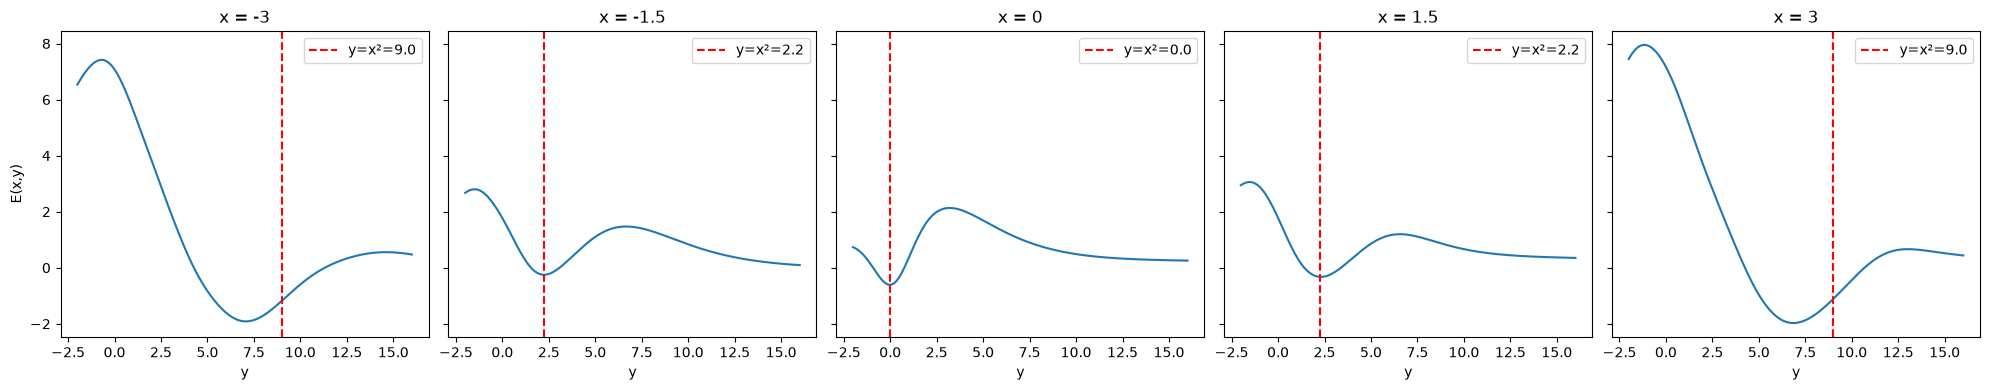

In [7]:
import matplotlib.pyplot as plt

def plot_energy_slices(model, x_values=[-3, -1.5, 0, 1.5, 3]):
    y_lin = torch.linspace(-2, 16, 200).unsqueeze(1)

    fig, axes = plt.subplots(1, len(x_values), figsize=(4*len(x_values), 4), sharey=True)
    for ax, x_val in zip(axes, x_values):
        x_fixed = torch.full_like(y_lin, x_val)
        with torch.no_grad():
            E = model(x_fixed, y_lin)
        ax.plot(y_lin.numpy(), E.numpy())
        ax.axvline(x_val**2, color="red", linestyle="--", label=f"y=x²={x_val**2:.1f}")
        ax.set_title(f"x = {x_val}")
        ax.set_xlabel("y")
        ax.legend()
    axes[0].set_ylabel("E(x,y)")
    plt.tight_layout()
    plt.savefig("energy_slices.png")
    plt.show()

plot_energy_slices(model)

Ce qu'on voit ici c'est que pour différentes vleurs fixées de x, x² en rouge touche bien le creux (presque) de E qui est représentée par la courbe bleue.

Pour le géomètre dans l'âme que je suis, nous allons visualiser en 3D ce que notre modèle a appris. Le model apprends g une fonction telle que E = g(x,y). Cette fonction g devrait dans l'idéal présenter un creux au niveau de la courbe 2D, y = x² et s'envoler vers le haut en dehors de cette zone.

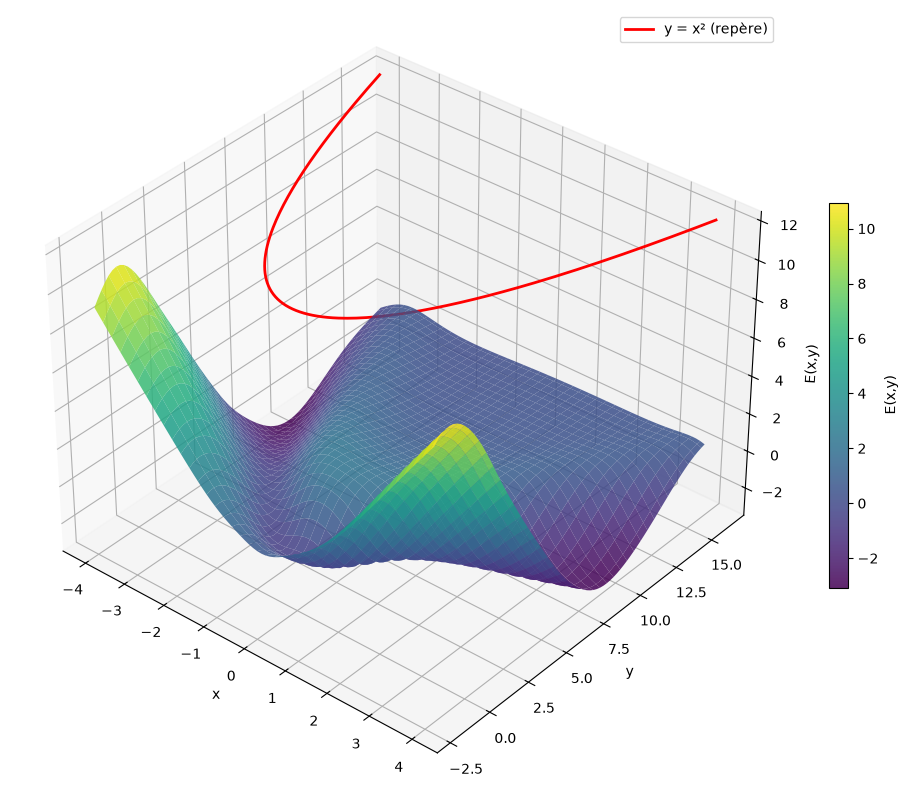

In [8]:
import matplotlib.pyplot as plt
import torch

def plot_energy_surface_3d(model, x_range=(-4, 4), y_range=(-2, 16), n=80):
    x_lin = torch.linspace(*x_range, n)
    y_lin = torch.linspace(*y_range, n)
    X, Y = torch.meshgrid(x_lin, y_lin, indexing="ij")

    X_flat = X.reshape(-1, 1)
    Y_flat = Y.reshape(-1, 1)
    with torch.no_grad():
        Z_flat = model(X_flat, Y_flat)
    Z = Z_flat.reshape(X.shape)

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(projection="3d")

    # surface d'énergie, colorée par la hauteur (creux bien visible en couleur foncée)
    surf = ax.plot_surface(
        X.numpy(), Y.numpy(), Z.numpy(),
        cmap="viridis", alpha=0.85, edgecolor="none"
    )
    fig.colorbar(surf, ax=ax, shrink=0.5, label="E(x,y)")

    # la courbe y=x² surélevée légèrement pour rester visible au-dessus de la surface
    x_curve = torch.linspace(*x_range, 200)
    y_curve = x_curve**2
    z_curve = torch.full_like(x_curve, Z.max().item() + 1)  # au-dessus, juste comme repère
    ax.plot(x_curve.numpy(), y_curve.numpy(), z_curve.numpy(),
            color="red", linewidth=2, label="y = x² (repère)")

    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("E(x,y)")
    ax.legend()
    ax.view_init(elev=35, azim=-50)  # angle choisi pour bien voir le sillon
    plt.tight_layout()
    plt.savefig("energy_surface_3d.png")
    plt.show()

plot_energy_surface_3d(model)

On voit bien que le modèle présente bien un creux sur la ligne de niveau y=x². C'est satisfaisant.
Ce qui serait intéressant est de voir si on pourrait dimunier le nombre de descente au bout duquel l'énergie converge en moyenne vers sa valeur critique. Celà permettrait de réduire le coût de l'inférence.